In [1]:
import numpy as np
import pandas as pd 

! pip install requests

In [2]:
import requests

In [3]:
# importing the countries.
url = "https://api.worldbank.org/countries?format=json&per_page=300"

response = requests.get(url)
response.status_code

200

In [4]:
data = response.json()
print(data[0])
print(len(data))

# 1- metadata
# 2- Actual data

{'page': 1, 'pages': 1, 'per_page': '300', 'total': 296}
2


In [5]:
countries= data[1]
countries= pd.DataFrame(countries)

In [9]:
countries["adminregion"][0]

{'id': '', 'iso2code': '', 'value': ''}

In [10]:
countries["region"]= countries["region"].apply(lambda x:x["value"])

In [11]:
countries["incomeLevel"]= countries["incomeLevel"].apply(lambda x:x["value"])

In [12]:
countries["lendingType"]= countries["lendingType"].apply(lambda x:x["value"])

In [13]:
countries.drop(columns=["adminregion","capitalCity"], inplace=True)

In [14]:
countries["region"].unique()

array(['Latin America & Caribbean ', 'Aggregates',
       'Middle East, North Africa, Afghanistan & Pakistan',
       'Sub-Saharan Africa ', 'Europe & Central Asia',
       'East Asia & Pacific', 'South Asia', 'North America'], dtype=object)

In [15]:
countries[countries["region"]=="Aggregates"]

,id,iso2Code,name,region,incomeLevel,lendingType,longitude,latitude
1,AFE,ZH,Africa Eastern and Southern,Aggregates,Aggregates,Aggregates,,
3,AFR,A9,Africa,Aggregates,Aggregates,Aggregates,,
4,AFW,ZI,Africa Western and Central,Aggregates,Aggregates,Aggregates,,
8,ARB,1A,Arab World,Aggregates,Aggregates,Aggregates,,
18,BEA,B4,East Asia & Pacific (IBRD-only countries),Aggregates,Aggregates,Aggregates,,
...,...,...,...,...,...,...,...,...
269,TSA,T5,South Asia (IDA & IBRD),Aggregates,Aggregates,Aggregates,,
270,TSS,T6,Sub-Saharan Africa (IDA & IBRD countries),Aggregates,Aggregates,Aggregates,,
278,UMC,XT,Upper middle income,Aggregates,Aggregates,Aggregates,,
288,WLD,1W,World,Aggregates,Aggregates,Aggregates,,


In [16]:
# code for indecators
base_url= "https://api.worldbank.org/v2/indicators?format=json"
response = requests.get(base_url)
response.status_code

200

In [17]:
indicators_data = response.json()

In [18]:
indicators_data[0]

{'page': 1, 'pages': 591, 'per_page': '50', 'total': 29544}

In [19]:
pd.DataFrame(indicators_data[1])

,id,name,unit,source,sourceNote,sourceOrganization,topics
0,1.0.HCount.1.90usd,Poverty Headcount ($1.90 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
1,1.0.HCount.2.5usd,Poverty Headcount ($2.50 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
2,1.0.HCount.Mid10to50,Middle Class ($10-50 a day) Headcount,,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
3,1.0.HCount.Ofcl,Official Moderate Poverty Rate-National,,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of data from Nation...,"[{'id': '11', 'value': 'Poverty '}]"
4,1.0.HCount.Poor4uds,Poverty Headcount ($4 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
5,1.0.HCount.Vul4to10,Vulnerable ($4-10 a day) Headcount,,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty headcount index measures the propo...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
6,1.0.PGap.1.90usd,Poverty Gap ($1.90 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty gap captures the mean aggregate in...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
7,1.0.PGap.2.5usd,Poverty Gap ($2.50 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty gap captures the mean aggregate in...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
8,1.0.PGap.Poor4uds,Poverty Gap ($4 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty gap captures the mean aggregate in...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"
9,1.0.PSev.1.90usd,Poverty Severity ($1.90 a day),,"{'id': '37', 'value': 'LAC Equity Lab'}",The poverty severity index combines informatio...,LAC Equity Lab tabulations of SEDLAC (CEDLAS a...,"[{'id': '11', 'value': 'Poverty '}]"


In [20]:
all_dfs = []

In [21]:
for i in range(1, 61):
    url = f"https://api.worldbank.org/v2/indicator?format=json&per_page=500&page={i}"

    response = requests.get(url)

    if response.status_code == 200:
        data = response.json()

        if len(data) < 2:
            print(f"No data at page {i}")
            continue

        indicators = data[1]

        df = pd.DataFrame([
            {
                "id": item["id"],
                "name": item["name"]
            }
            for item in indicators
        ])

        all_dfs.append(df)
        print(f"Page {i}: {len(df)} indicators collected")

    else:
        print(f"Failed to fetch page {i}, status code {response.status_code}")

Page 1: 500 indicators collected
Page 2: 500 indicators collected
Page 3: 500 indicators collected
Page 4: 500 indicators collected
Page 5: 500 indicators collected
Page 6: 500 indicators collected
Page 7: 500 indicators collected
Page 8: 500 indicators collected
Page 9: 500 indicators collected
Page 10: 500 indicators collected
Page 11: 500 indicators collected
Page 12: 500 indicators collected
Page 13: 500 indicators collected
Page 14: 500 indicators collected
Page 15: 500 indicators collected
Page 16: 500 indicators collected
Page 17: 500 indicators collected
Page 18: 500 indicators collected
Page 19: 500 indicators collected
Page 20: 500 indicators collected
Page 21: 500 indicators collected
Page 22: 500 indicators collected
Page 23: 500 indicators collected
Page 24: 500 indicators collected
Page 25: 500 indicators collected
Page 26: 500 indicators collected
Page 27: 500 indicators collected
Page 28: 500 indicators collected
Page 29: 500 indicators collected
Page 30: 500 indicators

In [22]:
url = "https://api.worldbank.org/v2/indicator?format=json&per_page=500"

response = requests.get(url)

indicators_data = response.json()

indicators_data[0]

{'page': 1, 'pages': 60, 'per_page': '500', 'total': 29544}

In [23]:
final_df= pd.concat(all_dfs, ignore_index=True)

In [24]:
final_df

,id,name
0,1.0.HCount.1.90usd,Poverty Headcount ($1.90 a day)
1,1.0.HCount.2.5usd,Poverty Headcount ($2.50 a day)
2,1.0.HCount.Mid10to50,Middle Class ($10-50 a day) Headcount
3,1.0.HCount.Ofcl,Official Moderate Poverty Rate-National
4,1.0.HCount.Poor4uds,Poverty Headcount ($4 a day)
...,...,...
29539,ytil_some_dfcl_all,Youth idle rate (% of persons with some degree...
29540,ytil_some_dfcl_fem,Youth idle rate (% of female persons with some...
29541,ytil_some_dfcl_male,Youth idle rate (% of male persons with some d...
29542,ytil_some_dfcl_rur,Youth idle rate (% of persons living in rural ...


In [25]:
import numpy as np
import pandas as pd
import requests
import time


# ------------------------------ World Bank countries endpoint------------------------------

url = "https://api.worldbank.org/v2/country?format=json&per_page=300"
response = requests.get(url)
data=response.json()
countries = data[1]
countries = pd.DataFrame(countries)
countries['region'] = countries['region'].apply(lambda x: x['value'])
countries['incomeLevel'] = countries['incomeLevel'].apply(lambda x: x['value'])
countries['lendingType'] = countries['lendingType'].apply(lambda x: x['value'])

countries.drop(columns=['adminregion'], inplace=True)
countries.rename(columns={'iso2Code':'country_id'}, inplace=True)

#------------------------------Getting List of API------------------------------ # not mentioning over here as we have to already decide the API before writing python code in Power BI.

#------------------------------ Getting data for the indicators------------------------------
indicator_groups = {
    "economic_activity_growth": [
        "NY.GDP.MKTP.KD.ZG",    # GDP growth (annual %)
        "NY.GDP.PCAP.CD"        # GDP per capita (current US$)
    ],
    "labour_market_indicators": [
        "SL.UEM.TOTL.ZS",       # Unemployment total
        "SL.UEM.1524.ZS",       # Unemployment youth total (ages 15-24)
        "SL.TLF.TOTL.IN"        # Labour force, total
    ],
    "trade_globalization": [
        "NE.EXP.GNFS.CD",       # Exports of goods and services (current US$)
        "NE.IMP.GNFS.CD"        # Imports of goods and services (current US$)
    ],
    "poverty_inequality": [
        "SI.POV.NAHC",          # Poverty headcount ratio at national poverty lines (% of population)
        "SI.POV.GINI"           # Gini index (measure of income inequality)
    ],
    "environmental_indicators": [
        "EG.FEC.RNEW.ZS",       # Renewable energy consumption (% of total final energy consumption)
        "AG.LND.FRST.ZS"        # Forest area (% of land area)
    ],
    "health_indicators": [
        "SP.DYN.LE00.IN",       # Life expectancy at birth
        "SP.DYN.IMRT.IN",       # Infant mortality rate
        "SH.H2O.BASW.ZS",       # Access to at least basic water services (% of population)
        "SH.XPD.CHEX.GD.ZS",    # Current health expenditure (% of GDP)
        "SH.IMM.IDPT",          # Immunization, DPT (% of children ages 12-23 months)
        "SH.IMM.MEAS",          # Immunization, measles (% of children ages 12-23 months)
        "SH.MMR.RISK.ZS",       # Risk of maternal death
        "SH.DTH.COMM.ZS",       # Deaths from communicable diseases (% of total)
        "SH.TBS.INCD",          # Tuberculosis incidence (per 100,000 people)
        "SH.STA.BRTC.ZS",       # Births attended by skilled health staff (%)
        "SH.STA.MMRT",          # Maternal mortality ratio (modeled estimate, per 100,000 live births)
        "SP.POP.65UP.TO.ZS",    # Population ages 65 and above (% of total population)
        "SH.HIV.INCD.ZS"        # HIV incidence rate (per 1,000 uninfected population ages 15-49)
    ],
    "technology_indicators": [
        "IT.NET.USER.ZS",       # Individuals using the Internet (% of population)
        "IT.CEL.SETS.P2"        # Mobile cellular subscriptions (per 100 people)
    ]
}


base_url = "https://api.worldbank.org/v2/country/all/indicator/{}?format=json&per_page=1000&page={}"

category_dataframes = {}

for category, indicators in indicator_groups.items():
    print(f"\nFetching data for category: {category}")

    all_dfs_for_category = []  # to hold DataFrames of all indicators in this category

    for indicator_code in indicators:
        print(f"  Fetching indicator: {indicator_code}")
        page = 1

        while True:
            # Prepare URL with indicator and page number
            url = base_url.format(indicator_code, page)  # modifying the above url with the page number and code

            # Request data
            response = requests.get(url)
            if response.status_code != 200:
                print(f"   Failed at page {page} with status code {response.status_code}")
                break

            data = response.json()
            if len(data) < 2:
                print(f"   No data for indicator {indicator_code} on page {page}")
                break

            total_pages = data[0]['pages']  # extracting total pages
            records = data[1]

            # Normalize JSON to flat table
            df = pd.json_normalize(records)

            # Select and rename useful columns
            df = df[
                [
                    'country.id',
                    'country.value',
                    'indicator.id',
                    'indicator.value',
                    'date',
                    'value'
                ]
            ].rename(columns={
                'country.id': 'country_id',
                'country.value': 'country_name',
                'indicator.id': 'indicator_id',
                'indicator.value': 'indicator_name',
                'date': 'year'
            })

            # Filter for years > 2015
            df = df[df['year'].astype(int) > 2015]

            # Append current page data
            all_dfs_for_category.append(df)

            # Check if last page
            if page >= total_pages:  #running loop till the last page.
                break
            else:
                page += 1
                time.sleep(0.2)  # polite pause

    # Concatenate all dataframes for this category if any data fetched
    if all_dfs_for_category:
        combined_df = pd.concat(all_dfs_for_category, ignore_index=True)
        category_dataframes[category] = combined_df
        print(f"   Total rows collected for {category}: {len(combined_df)}")
    else:
        print(f"   No data collected for {category}")

print("\n Data fetching complete for all categories.")


#------------------------------ Getting different dataframe from each set of indicators ------------------------------

economic_activity = category_dataframes.get("economic_activity_growth", pd.DataFrame())
labor_market_jobs = category_dataframes.get("labour_market_indicators", pd.DataFrame())
trade_globalization = category_dataframes.get("trade_globalization", pd.DataFrame())
poverty_inequality = category_dataframes.get("poverty_inequality", pd.DataFrame())
environmental_indicators = category_dataframes.get("environmental_indicators", pd.DataFrame())
health_indicators = category_dataframes.get("health_indicators", pd.DataFrame())
technology_indicators = category_dataframes.get("technology_indicators", pd.DataFrame())


#------------------------------ Merge example for each category - adjust 'countries' DataFrame accordingly ------------------------------

economic = pd.merge(economic_activity, countries, on='country_id', how='inner')
labour_market = pd.merge(labor_market_jobs, countries, on='country_id', how='inner')
trade = pd.merge(trade_globalization, countries, on='country_id', how='inner')
poverty = pd.merge(poverty_inequality, countries, on='country_id', how='inner')
environment = pd.merge(environmental_indicators, countries, on='country_id', how='inner')
health = pd.merge(health_indicators, countries, on='country_id', how='inner')
technology = pd.merge(technology_indicators, countries, on='country_id', how='inner')


#------------------------------ Dropping un-necessary columns ------------------------------

economic.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
labour_market.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
trade.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
poverty.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
environment.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
health.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)
technology.drop(columns=["indicator_id","name","capitalCity","id"], inplace=True)



Fetching data for category: economic_activity_growth
  Fetching indicator: NY.GDP.MKTP.KD.ZG
  Fetching indicator: NY.GDP.PCAP.CD
   Total rows collected for economic_activity_growth: 5320

Fetching data for category: labour_market_indicators
  Fetching indicator: SL.UEM.TOTL.ZS
   Failed at page 4 with status code 400
  Fetching indicator: SL.UEM.1524.ZS
  Fetching indicator: SL.TLF.TOTL.IN
   Total rows collected for labour_market_indicators: 5780

Fetching data for category: trade_globalization
  Fetching indicator: NE.EXP.GNFS.CD
  Fetching indicator: NE.IMP.GNFS.CD
   Total rows collected for trade_globalization: 5320

Fetching data for category: poverty_inequality
  Fetching indicator: SI.POV.NAHC
  Fetching indicator: SI.POV.GINI


C:\Users\GOKUL\AppData\Local\Temp\ipykernel_20892\2983646230.py:135: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_df = pd.concat(all_dfs_for_category, ignore_index=True)


   Total rows collected for poverty_inequality: 5320

Fetching data for category: environmental_indicators
  Fetching indicator: EG.FEC.RNEW.ZS
  Fetching indicator: AG.LND.FRST.ZS
   Total rows collected for environmental_indicators: 5320

Fetching data for category: health_indicators
  Fetching indicator: SP.DYN.LE00.IN
  Fetching indicator: SP.DYN.IMRT.IN
  Fetching indicator: SH.H2O.BASW.ZS
  Fetching indicator: SH.XPD.CHEX.GD.ZS
  Fetching indicator: SH.IMM.IDPT
  Fetching indicator: SH.IMM.MEAS
  Fetching indicator: SH.MMR.RISK.ZS
  Fetching indicator: SH.DTH.COMM.ZS
  Fetching indicator: SH.TBS.INCD
  Fetching indicator: SH.STA.BRTC.ZS
  Fetching indicator: SH.STA.MMRT
  Fetching indicator: SP.POP.65UP.TO.ZS
  Fetching indicator: SH.HIV.INCD.ZS
   Total rows collected for health_indicators: 34580

Fetching data for category: technology_indicators
  Fetching indicator: IT.NET.USER.ZS
  Fetching indicator: IT.CEL.SETS.P2
   Total rows collected for technology_indicators: 5320

 Da

In [25]:
economic.to_csv("economic.csv")
labour_market.to_csv("labour_market.csv")
trade.to_csv("trade.csv")
poverty.to_csv("poverty.csv")
environment.to_csv("environment.csv")
health.to_csv("health.csv")
technology.to_csv("technology.csv")


In [26]:
health

,country_id,country_name,indicator_name,year,value,region,incomeLevel,lendingType,longitude,latitude
0,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2025,NaN,Aggregates,Aggregates,Aggregates,,
1,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2024,65.349930,Aggregates,Aggregates,Aggregates,,
2,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2023,65.146228,Aggregates,Aggregates,Aggregates,,
3,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2022,64.487152,Aggregates,Aggregates,Aggregates,,
4,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2021,62.979999,Aggregates,Aggregates,Aggregates,,
...,...,...,...,...,...,...,...,...,...,...
34575,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2020,1.900000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
34576,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2019,2.300000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
34577,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2018,2.700000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
34578,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2017,3.600000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312


In [29]:
df_wide = health.pivot_table(index=["country_name","year"],
                             columns="indicator_name",
                             values="value"
                             )



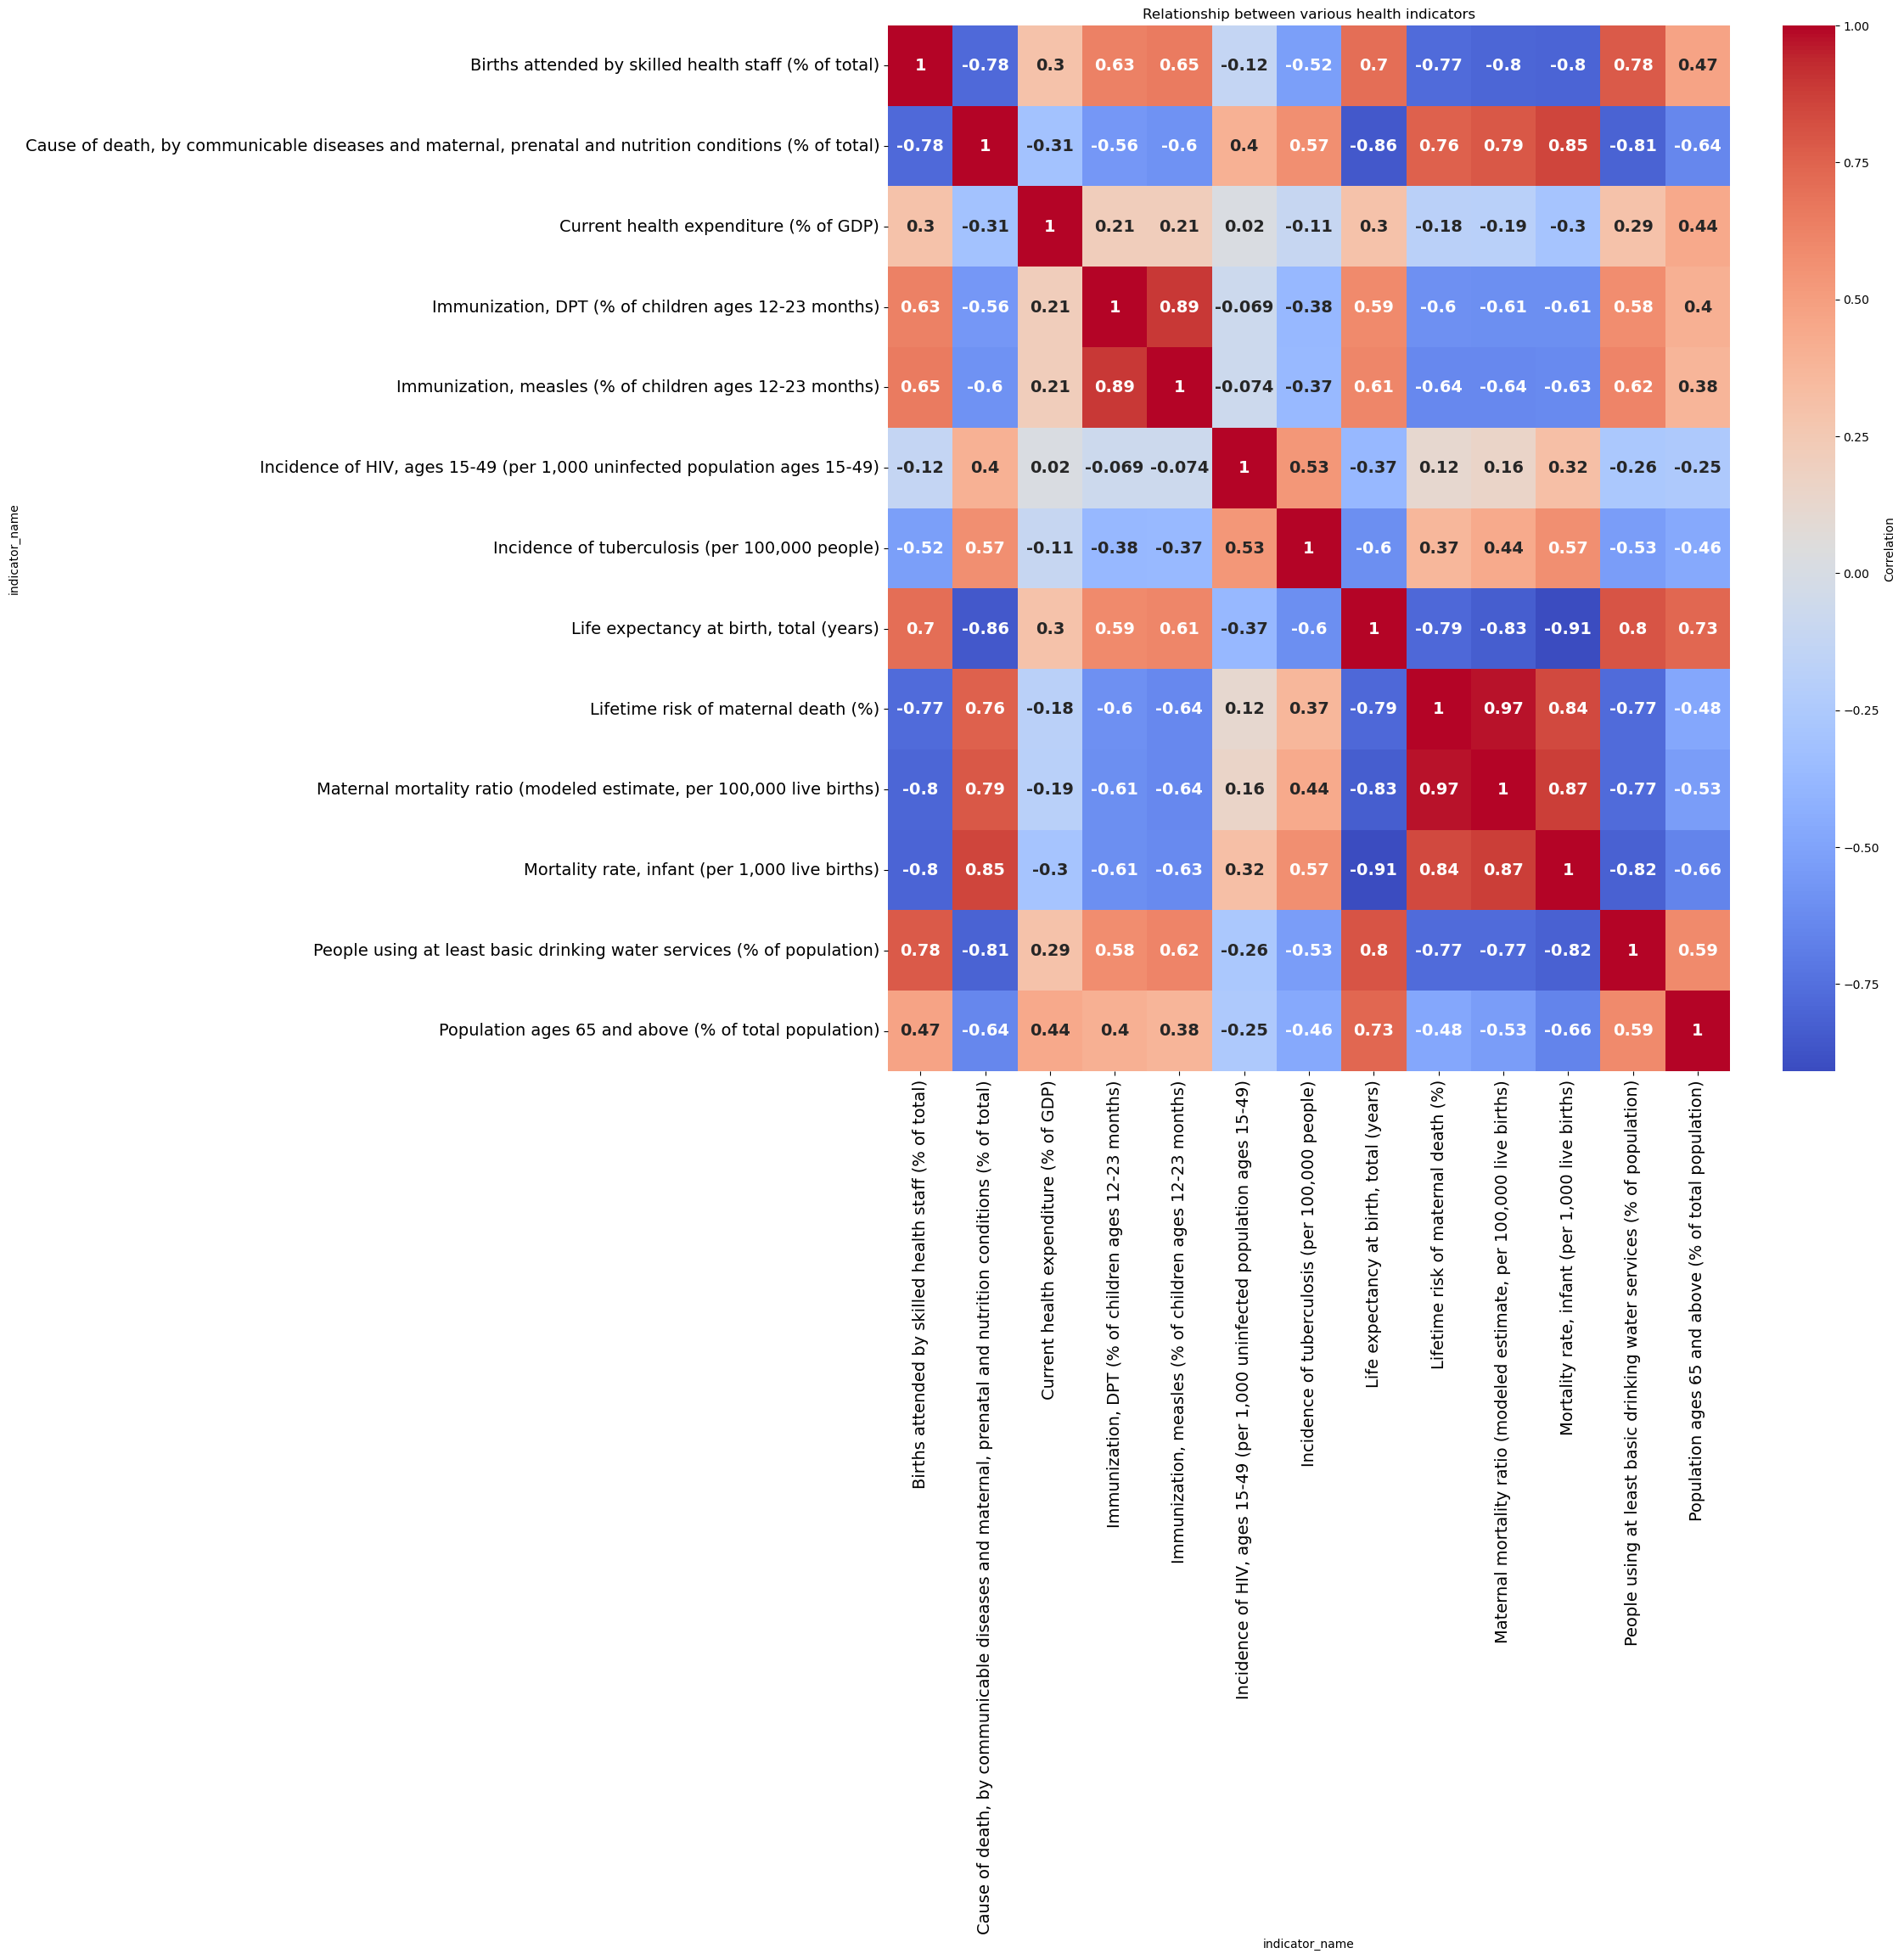

In [31]:

corr = df_wide.corr()
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16,16), facecolor="none")
ax = sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    cbar_kws={"label":"Correlation"},
    annot_kws={"fontsize":14, "fontweight":"bold"}
)
plt.title("Relationship between various health indicators")

ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)
plt.show()


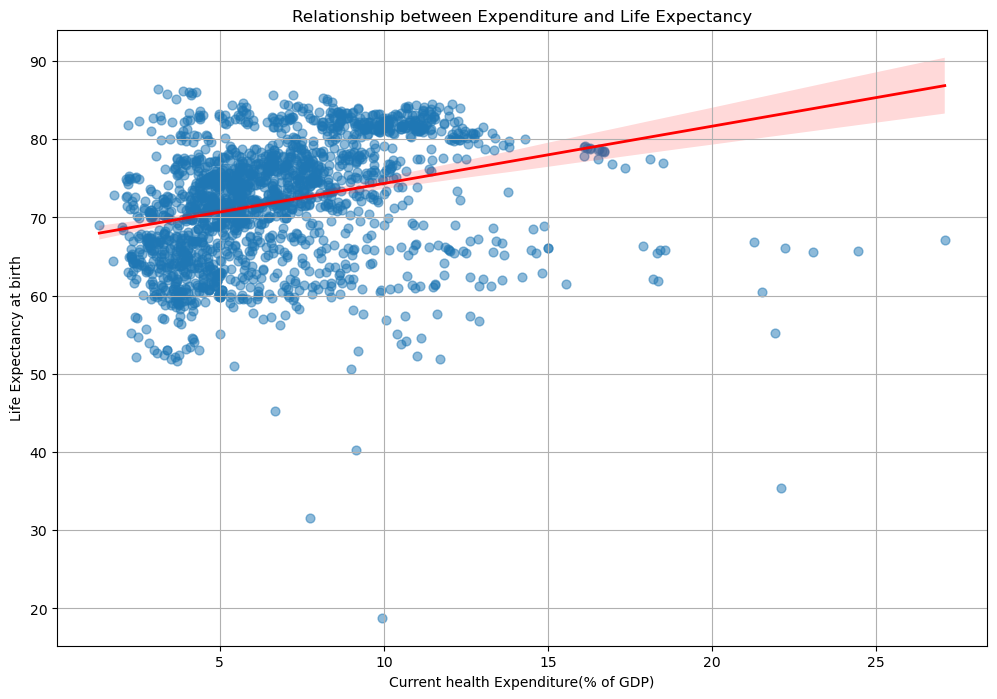

In [33]:
df_pivot = health.pivot(
    index=["country_name", "year"],
    columns="indicator_name",
    values="value",
).reset_index()

plt.figure(figsize=(12, 8), facecolor="none")

ax = sns.regplot(
    data=df_pivot,
    x="Current health expenditure (% of GDP)",
    y="Life expectancy at birth, total (years)",
    scatter_kws={"alpha": 0.5, "s": 40},
    line_kws={"color": "red", "lw": 2},
)

plt.title("Relationship between Expenditure and Life Expectancy")
plt.xlabel("Current health Expenditure(% of GDP)")
plt.ylabel("Life Expectancy at birth")
plt.grid(True)